# 03 - Look-alikes, clusters and the two splits (Week 4)

Week 3 found exact copies (MD5) and near copies (pHash). pHash compares a tiny 8x8 summary of the picture, so it misses copies that were **cropped differently, re-contrasted or overlaid with a ruler**. Here we add a third check:

- **Look-alike:** a pretrained ResNet-50 turns each (cropped, 224x224) image into 2,048 numbers that describe its content. Two images whose vectors point the same way (cosine similarity >= 0.95) are treated as copies.

**Clusters:** every link (exact, near, look-alike) joins two images. Union-find follows chains (A~B and B~C puts A, B, C together), so each cluster is one underlying scan and its copies.

**Two splits** every model will be trained and tested on:
- **original** - the dataset's own Training/Testing folders (15% of Training becomes validation). Leaky.
- **clean** - one image per cluster, conflicting-label clusters removed, 70/15/15 stratified. No cluster can appear in two splits.

Code: `src/splits.py`. Model weights are stored in `D:/Brain-Tumor/.cache`, not on C:.

In [1]:
import os, sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from src import splits as s
from src import data as d

d.set_seed(d.SEED)
VERSIONS = ['v1', 'v2']
AUDIT = {v: Path('outputs/audit') / v for v in VERSIONS}
SPLITS = Path('outputs/splits')
print('Model weights folder:', os.environ['HF_HOME'])

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model weights folder: D:\Brain-Tumor\.cache\huggingface


## 1. ResNet-50 features (float32)
*Note:* on this GTX 1650 Ti, half precision (AMP) made cuDNN return NaN for batches of 48+ images, so features are computed in float32 (correct and still fast). Features are saved and re-used.

In [2]:
table, hashes, pairs, feats, info = {}, {}, {}, {}, []
for v in VERSIONS:
    table[v] = pd.read_csv(SPLITS / f'{v}_cache224.csv')
    hashes[v] = pd.read_csv(AUDIT[v] / 'hashes.csv')
    pairs[v] = pd.read_csv(AUDIT[v] / 'pairs.csv')
    start = time.perf_counter()
    feats[v] = s.extract_features(SPLITS / f'{v}_cache224.csv', AUDIT[v] / 'features_resnet50.npy')
    norms = np.linalg.norm(feats[v], axis=1)
    info.append({'version': v, 'shape': feats[v].shape, 'seconds (0 = loaded from file)': round(time.perf_counter() - start, 1),
                 'any_NaN': bool(np.isnan(feats[v]).any()), 'norm_min': round(norms.min(), 4), 'norm_max': round(norms.max(), 4)})
pd.DataFrame(info)

,version,shape,seconds (0 = loaded from file),any_NaN,norm_min,norm_max
0,v1,"(7023, 2048)",0.1,False,1.0,1.0
1,v2,"(7200, 2048)",0.1,False,1.0,1.0


## 2. Look-alike pairs (cosine similarity on the GPU)

In [3]:
look, rows = {}, []
for v in VERSIONS:
    torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    i, j, sim = s.cosine_pairs(feats[v])
    torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    look[v] = s.lookalike_table(table[v], i, j, sim)
    look[v].to_csv(AUDIT[v] / 'lookalike_pairs.csv', index=False)
    rng = np.random.default_rng(d.SEED)
    a, b = rng.integers(0, len(feats[v]), 20000), rng.integers(0, len(feats[v]), 20000)
    random_cos = np.sum(feats[v][a] * feats[v][b], axis=1)
    rows.append({'version': v, 'gpu_seconds': round(seconds, 3),
                 'peak_vram_MB': round(torch.cuda.max_memory_allocated() / 1e6, 1),
                 'max_diff_vs_numpy': s.verify_cosine(feats[v], i, j, sim),
                 'random_pair_cos_mean': round(float(random_cos.mean()), 3),
                 'random_pair_cos_99%': round(float(np.percentile(random_cos, 99)), 3),
                 **{f'pairs_cos>={c}': int((look[v]['cosine'] >= c).sum()) for c in (0.93, 0.95, 0.97)}})
pd.DataFrame(rows)

,version,gpu_seconds,peak_vram_MB,max_diff_vs_numpy,random_pair_cos_mean,random_pair_cos_99%,pairs_cos>=0.93,pairs_cos>=0.95,pairs_cos>=0.97
0,v1,0.326,181.6,0.000002,0.634,0.834,8540,5464,2338
1,v2,0.141,185.9,0.000001,0.635,0.833,8116,5024,1870


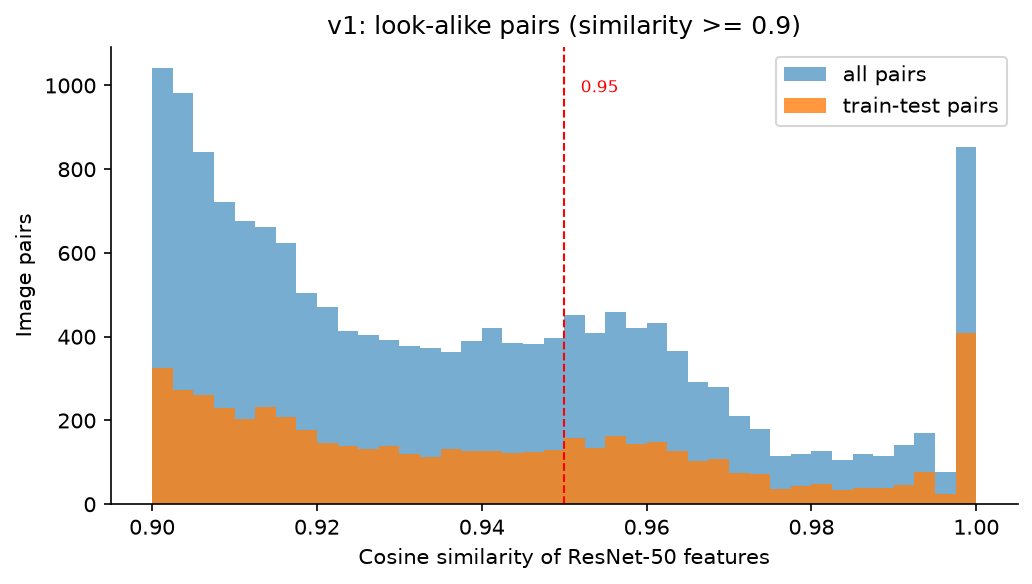

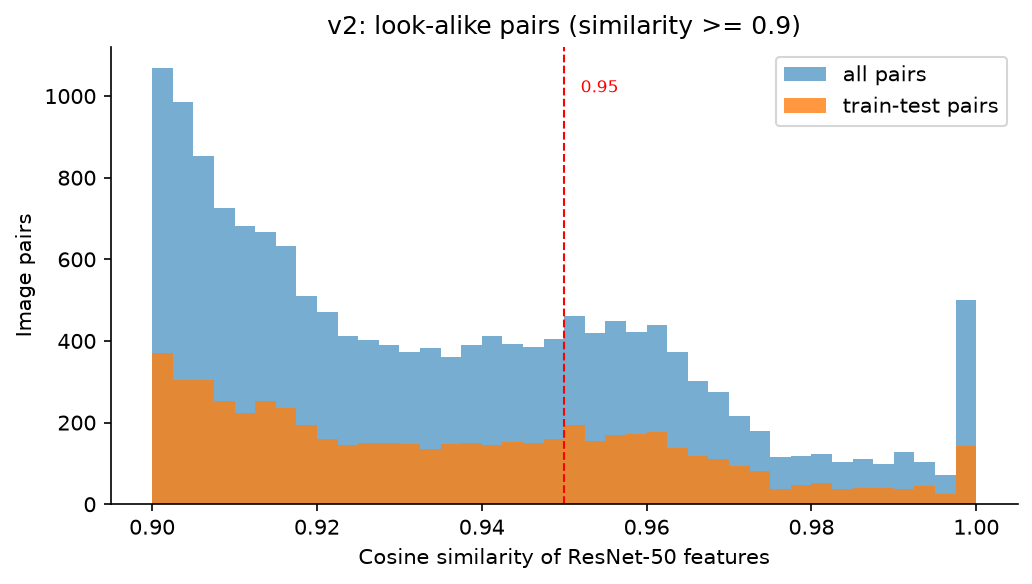

In [4]:
for v in VERSIONS:
    display(ShowImage(filename=str(s.plot_similarity_hist(look[v], AUDIT[v], v))))

### Pairs just above 0.95 that pHash did **not** find (eye check of the threshold)

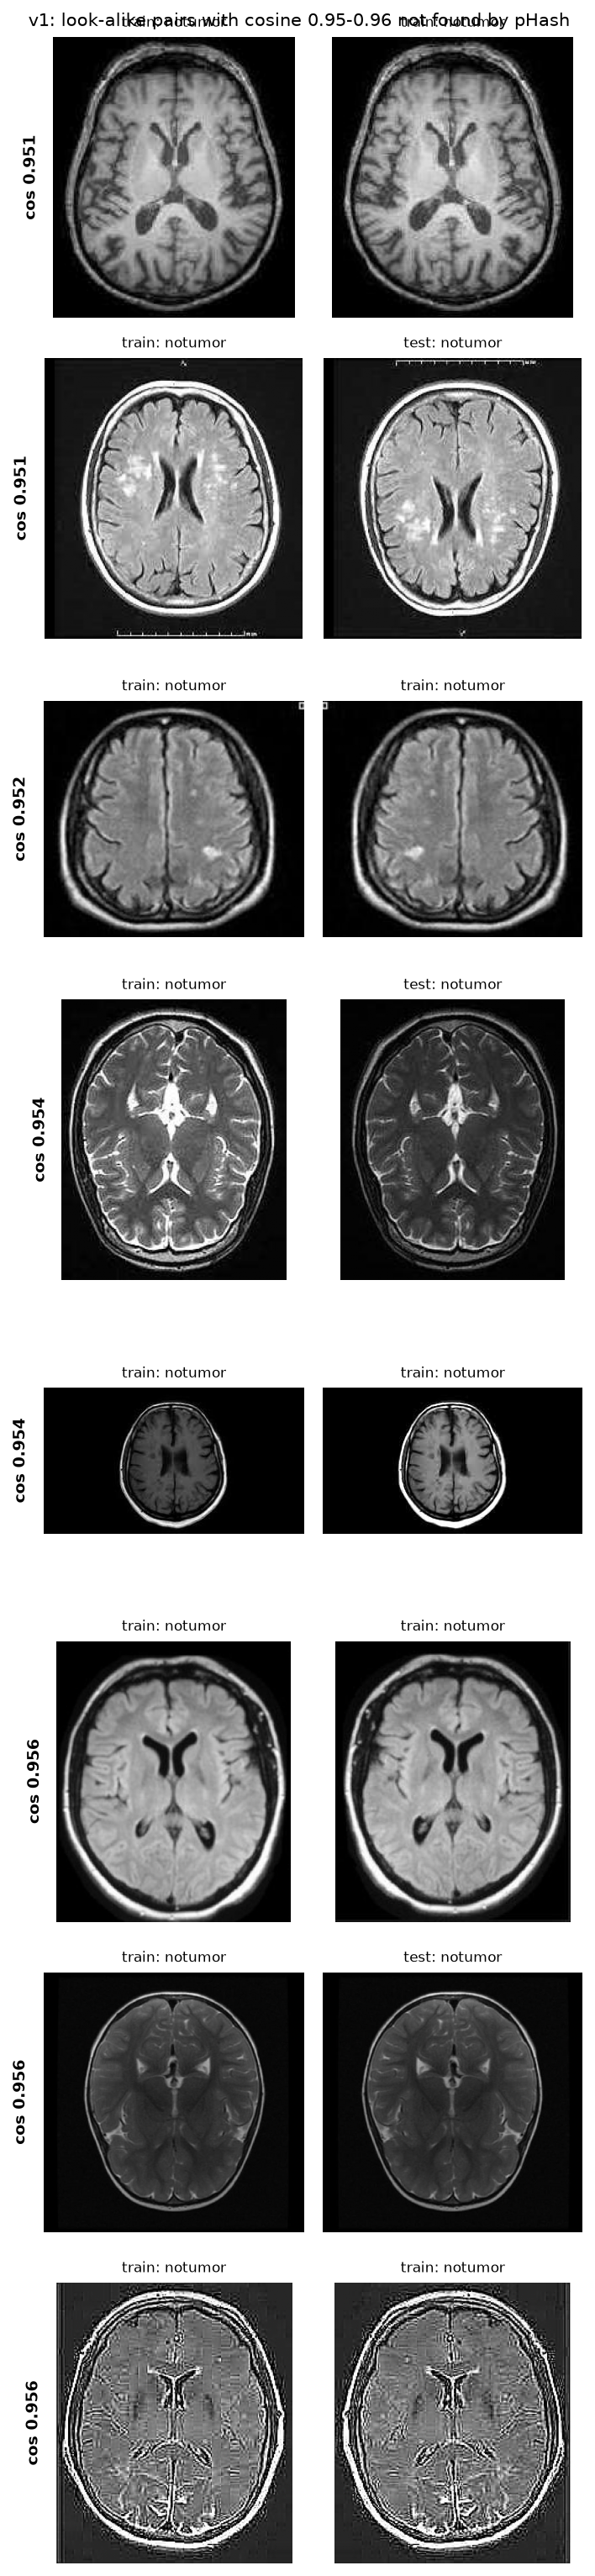

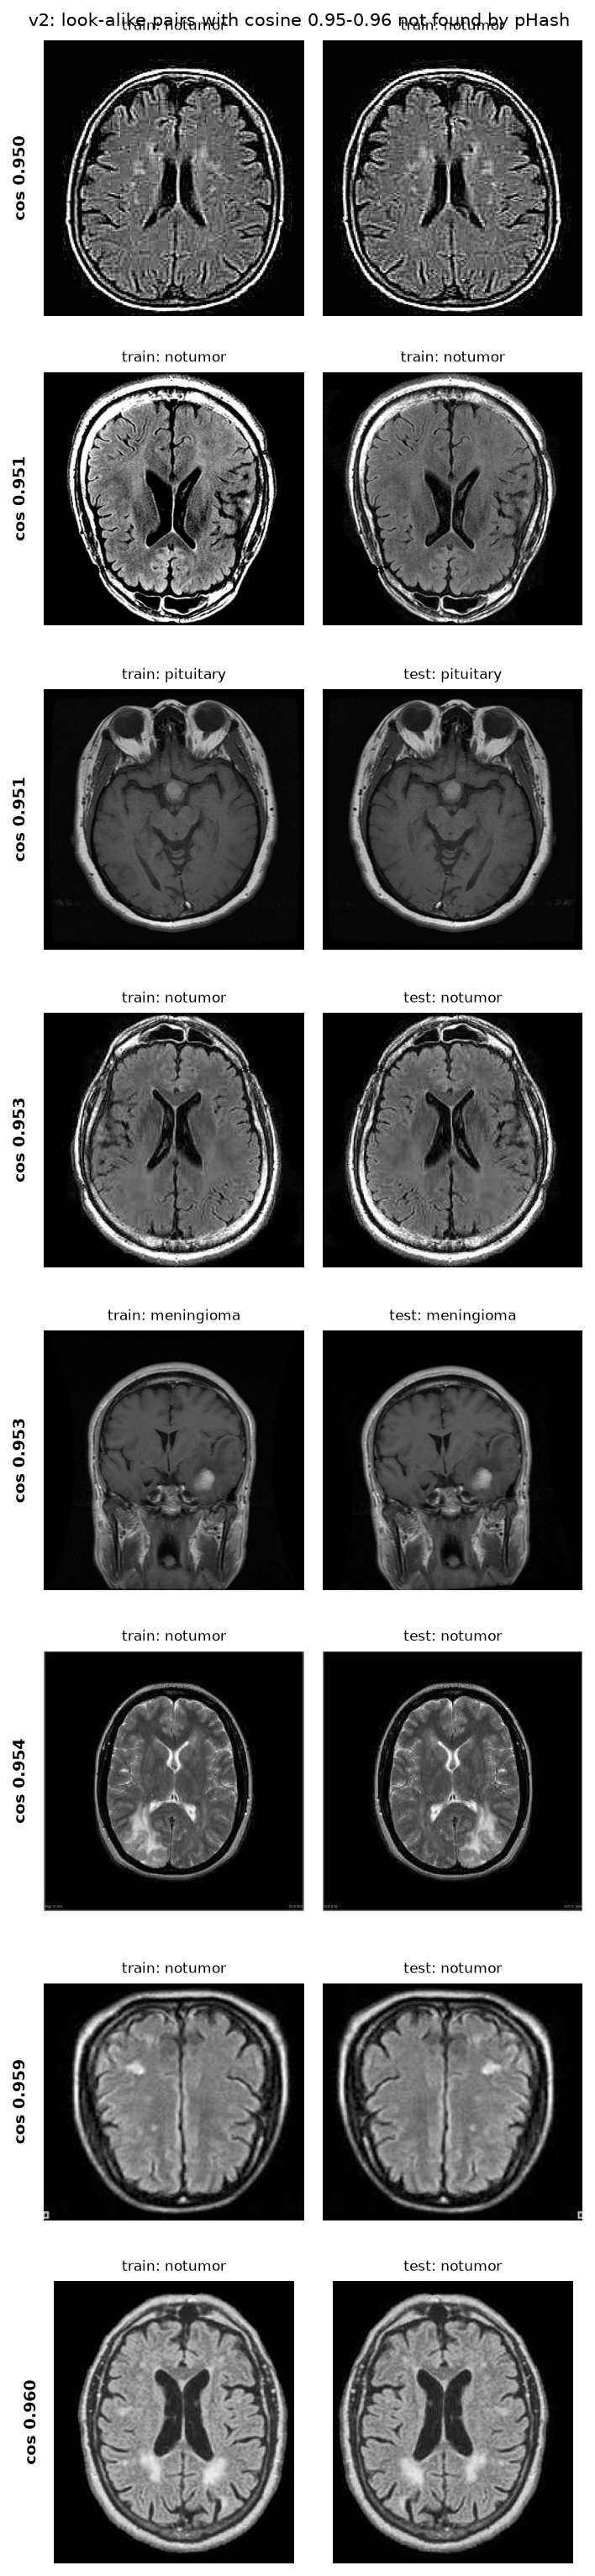

In [5]:
for v in VERSIONS:
    display(ShowImage(filename=str(s.plot_lookalike_examples(look[v], pairs[v], AUDIT[v], v, n=8, seed=7))))

## 3. Clusters (exact + near + look-alike, union-find)
Sensitivity check first: how big do clusters get at cosine 0.93 / 0.95 / 0.97? (A giant cluster would mean the threshold links different scans.)

In [6]:
sens = []
for v in VERSIONS:
    for c in (0.93, 0.95, 0.97):
        cl = s.build_clusters(table[v], hashes[v], pairs[v], look[v], cos=c)
        sens.append({'version': v, 'cosine': c, **s.cluster_stats(cl),
                     'test_leak_any_%': s.leak_table(cl, pairs[v], look[v], cos=c)['any (cluster)']})
pd.DataFrame(sens)

,version,cosine,images,clusters,clusters_2plus,largest_cluster,largest_%_of_images,conflict_clusters,images_in_conflict_clusters,test_leak_any_%
0,v1,0.93,7023,2754,1529,82,1.17,18,261,81.16
1,v1,0.95,7023,3483,1290,47,0.67,17,125,70.25
2,v1,0.97,7023,4366,1032,41,0.58,16,96,56.98
3,v2,0.93,7200,2829,1579,96,1.33,25,343,76.50
4,v2,0.95,7200,3607,1348,47,0.65,24,175,63.06
5,v2,0.97,7200,4585,1079,36,0.50,22,136,48.38


In [7]:
clusters = {}
for v in VERSIONS:
    clusters[v] = s.build_clusters(table[v], hashes[v], pairs[v], look[v])   # cosine 0.95, pHash T=5
    clusters[v].to_csv(AUDIT[v] / 'clusters.csv', index=False)
    sizes = clusters[v].groupby('cluster_id').size()
    print(v, s.cluster_stats(clusters[v]))
    print('   cluster sizes:', sizes.value_counts().sort_index().head(10).to_dict(), '...')

v1 {'images': 7023, 'clusters': 3483, 'clusters_2plus': 1290, 'largest_cluster': 47, 'largest_%_of_images': np.float64(0.67), 'conflict_clusters': 17, 'images_in_conflict_clusters': 125}
   cluster sizes: {1: 2193, 2: 793, 3: 125, 4: 141, 5: 45, 6: 53, 7: 19, 8: 22, 9: 10, 10: 9} ...


v2 {'images': 7200, 'clusters': 3607, 'clusters_2plus': 1348, 'largest_cluster': 47, 'largest_%_of_images': np.float64(0.65), 'conflict_clusters': 24, 'images_in_conflict_clusters': 175}
   cluster sizes: {1: 2259, 2: 813, 3: 156, 4: 154, 5: 37, 6: 59, 7: 21, 8: 20, 9: 8, 10: 13} ...


## 4. Clusters whose copies have different labels

In [8]:
for v in VERSIONS:
    report = s.conflict_report(clusters[v])
    report.to_csv(AUDIT[v] / 'conflict_clusters.csv', index=False)
    print(f'{v}: {len(report)} conflicting clusters, {int(report["size"].sum())} images')
    display(report.head(10))

v1: 17 conflicting clusters, 125 images


,cluster_id,size,labels,splits
0,2609,30,glioma:12 + meningioma:15 + notumor:3,test + train
1,2618,23,glioma:9 + meningioma:12 + notumor:2,test + train
2,251,9,glioma:5 + meningioma:4,test + train
3,6152,7,glioma:3 + meningioma:4,test + train
4,6720,7,glioma:2 + notumor:5,test + train
5,2371,6,glioma:5 + meningioma:1,train
6,2615,5,glioma:2 + meningioma:3,train
7,2471,5,glioma:1 + meningioma:4,train
8,2146,5,glioma:1 + meningioma:4,train
9,5884,5,glioma:4 + meningioma:1,test + train


v2: 24 conflicting clusters, 175 images


,cluster_id,size,labels,splits
0,6022,37,glioma:13 + meningioma:22 + notumor:2,test + train
1,6175,26,glioma:13 + meningioma:12 + notumor:1,test + train
2,6307,10,glioma:5 + meningioma:5,test + train
3,6242,10,glioma:5 + meningioma:5,test + train
4,6396,7,glioma:1 + meningioma:6,test + train
5,1284,6,glioma:2 + meningioma:4,test + train
6,6012,6,glioma:4 + meningioma:2,test + train
7,2078,6,glioma:5 + meningioma:1,train
8,5723,6,glioma:4 + meningioma:2,test + train
9,5807,5,glioma:4 + meningioma:1,test + train


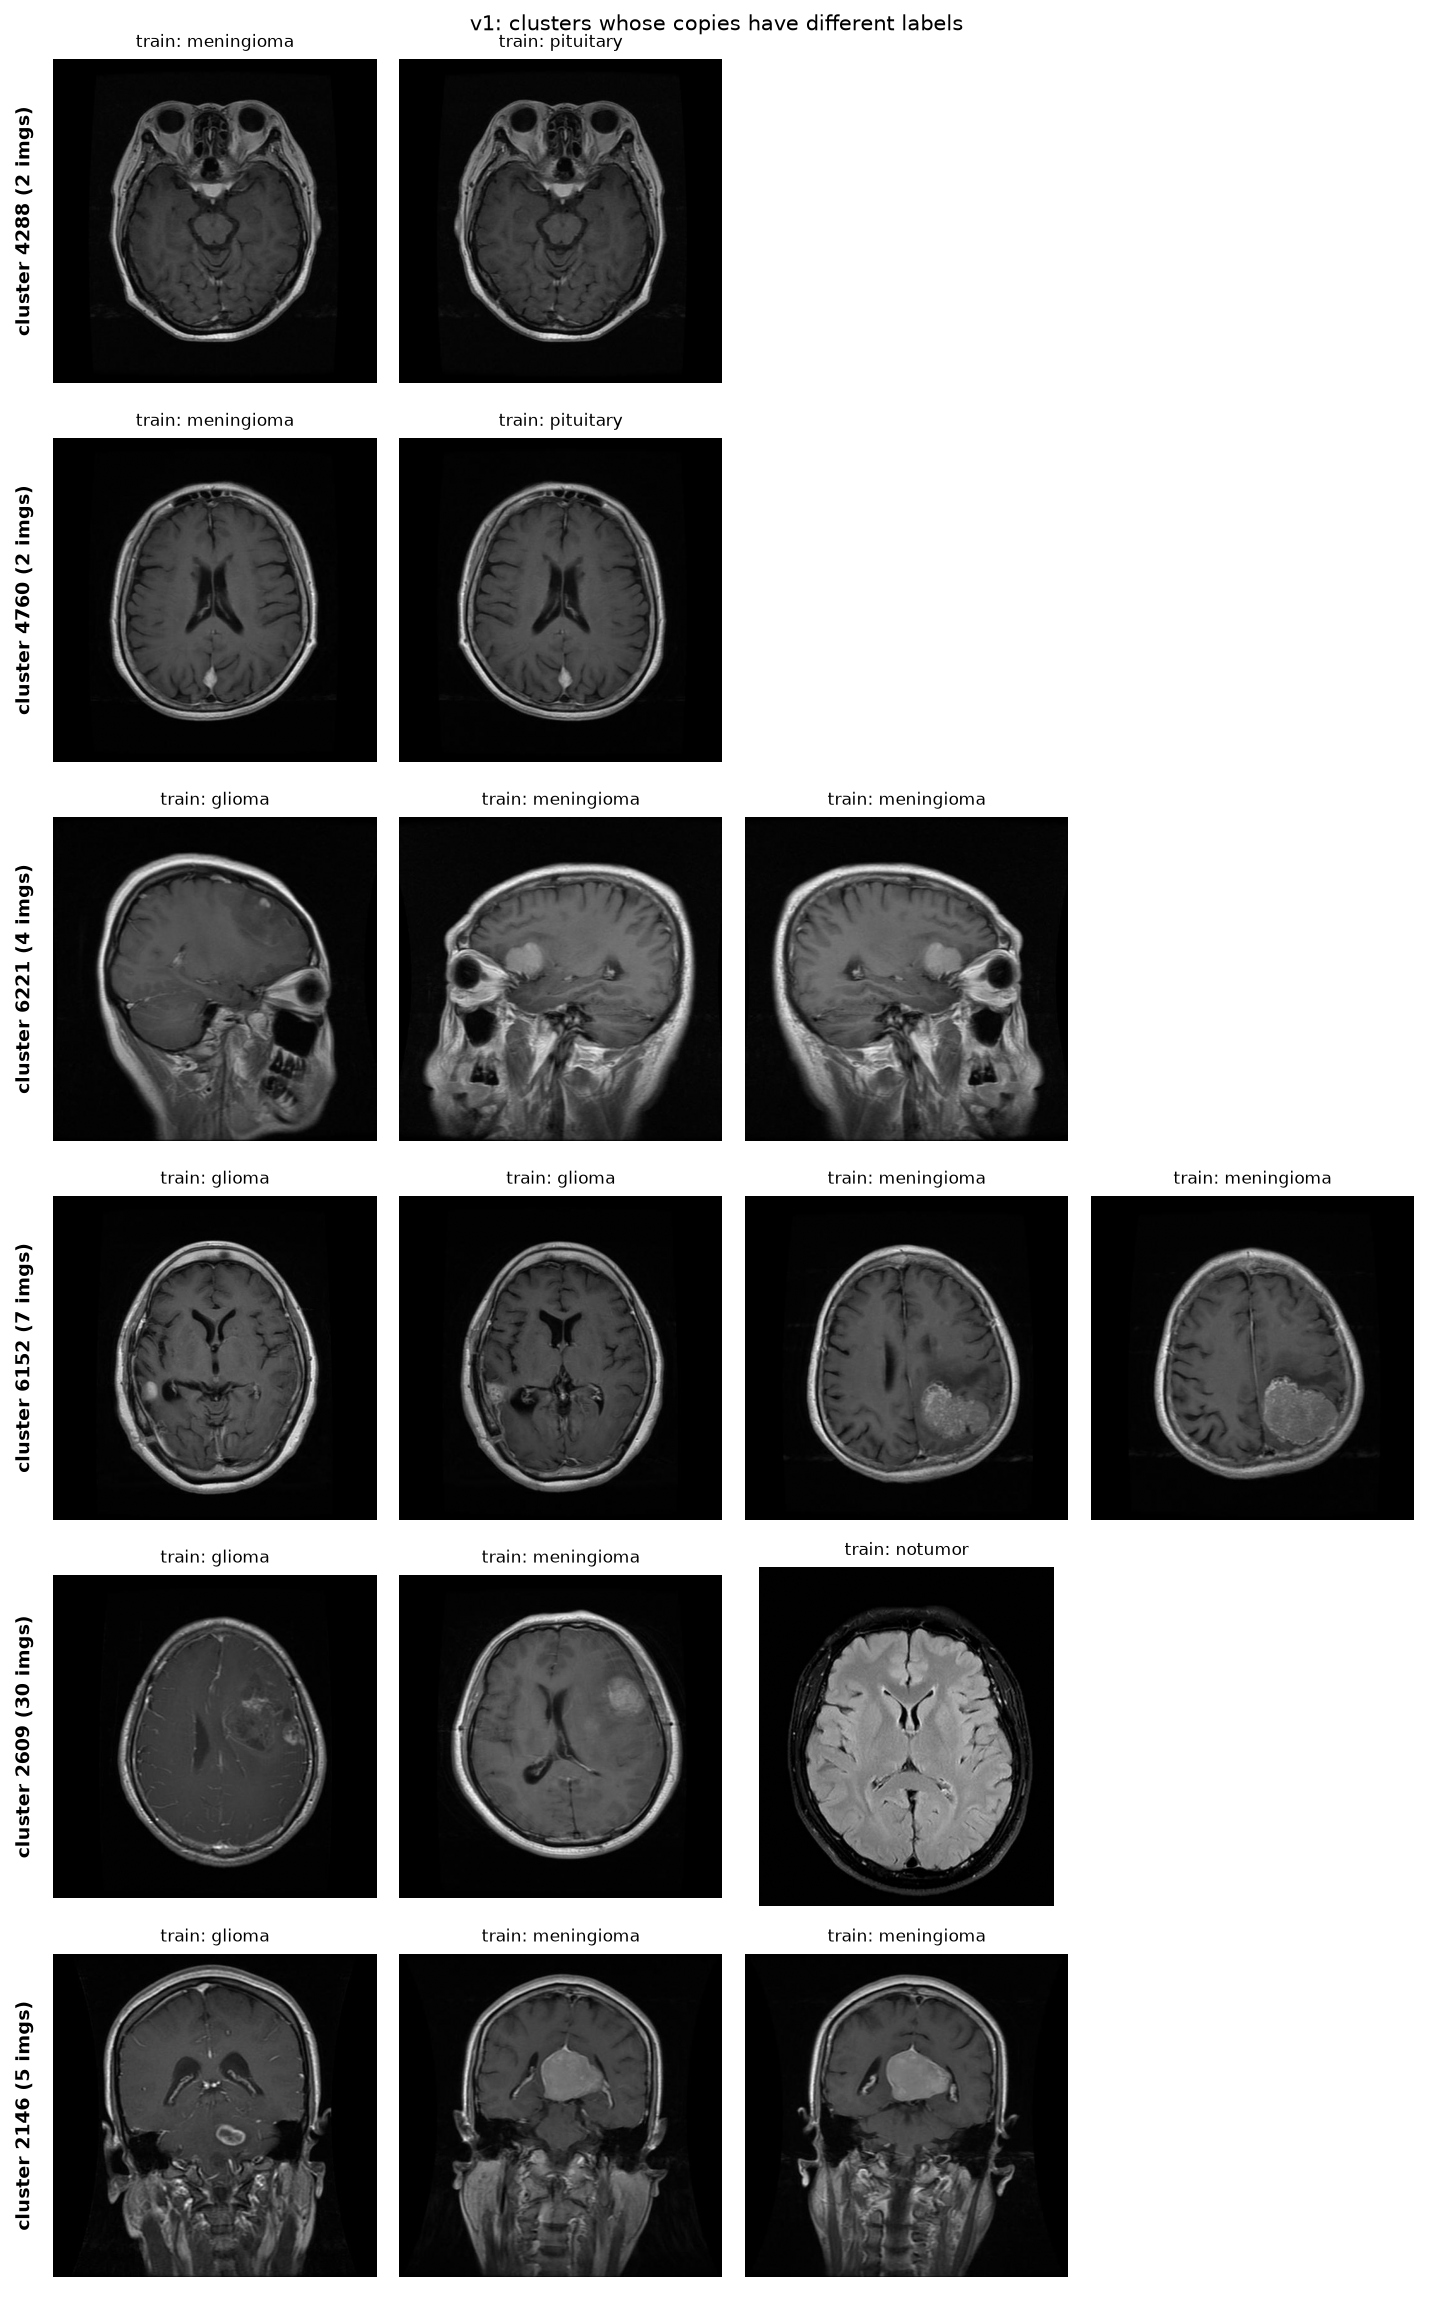

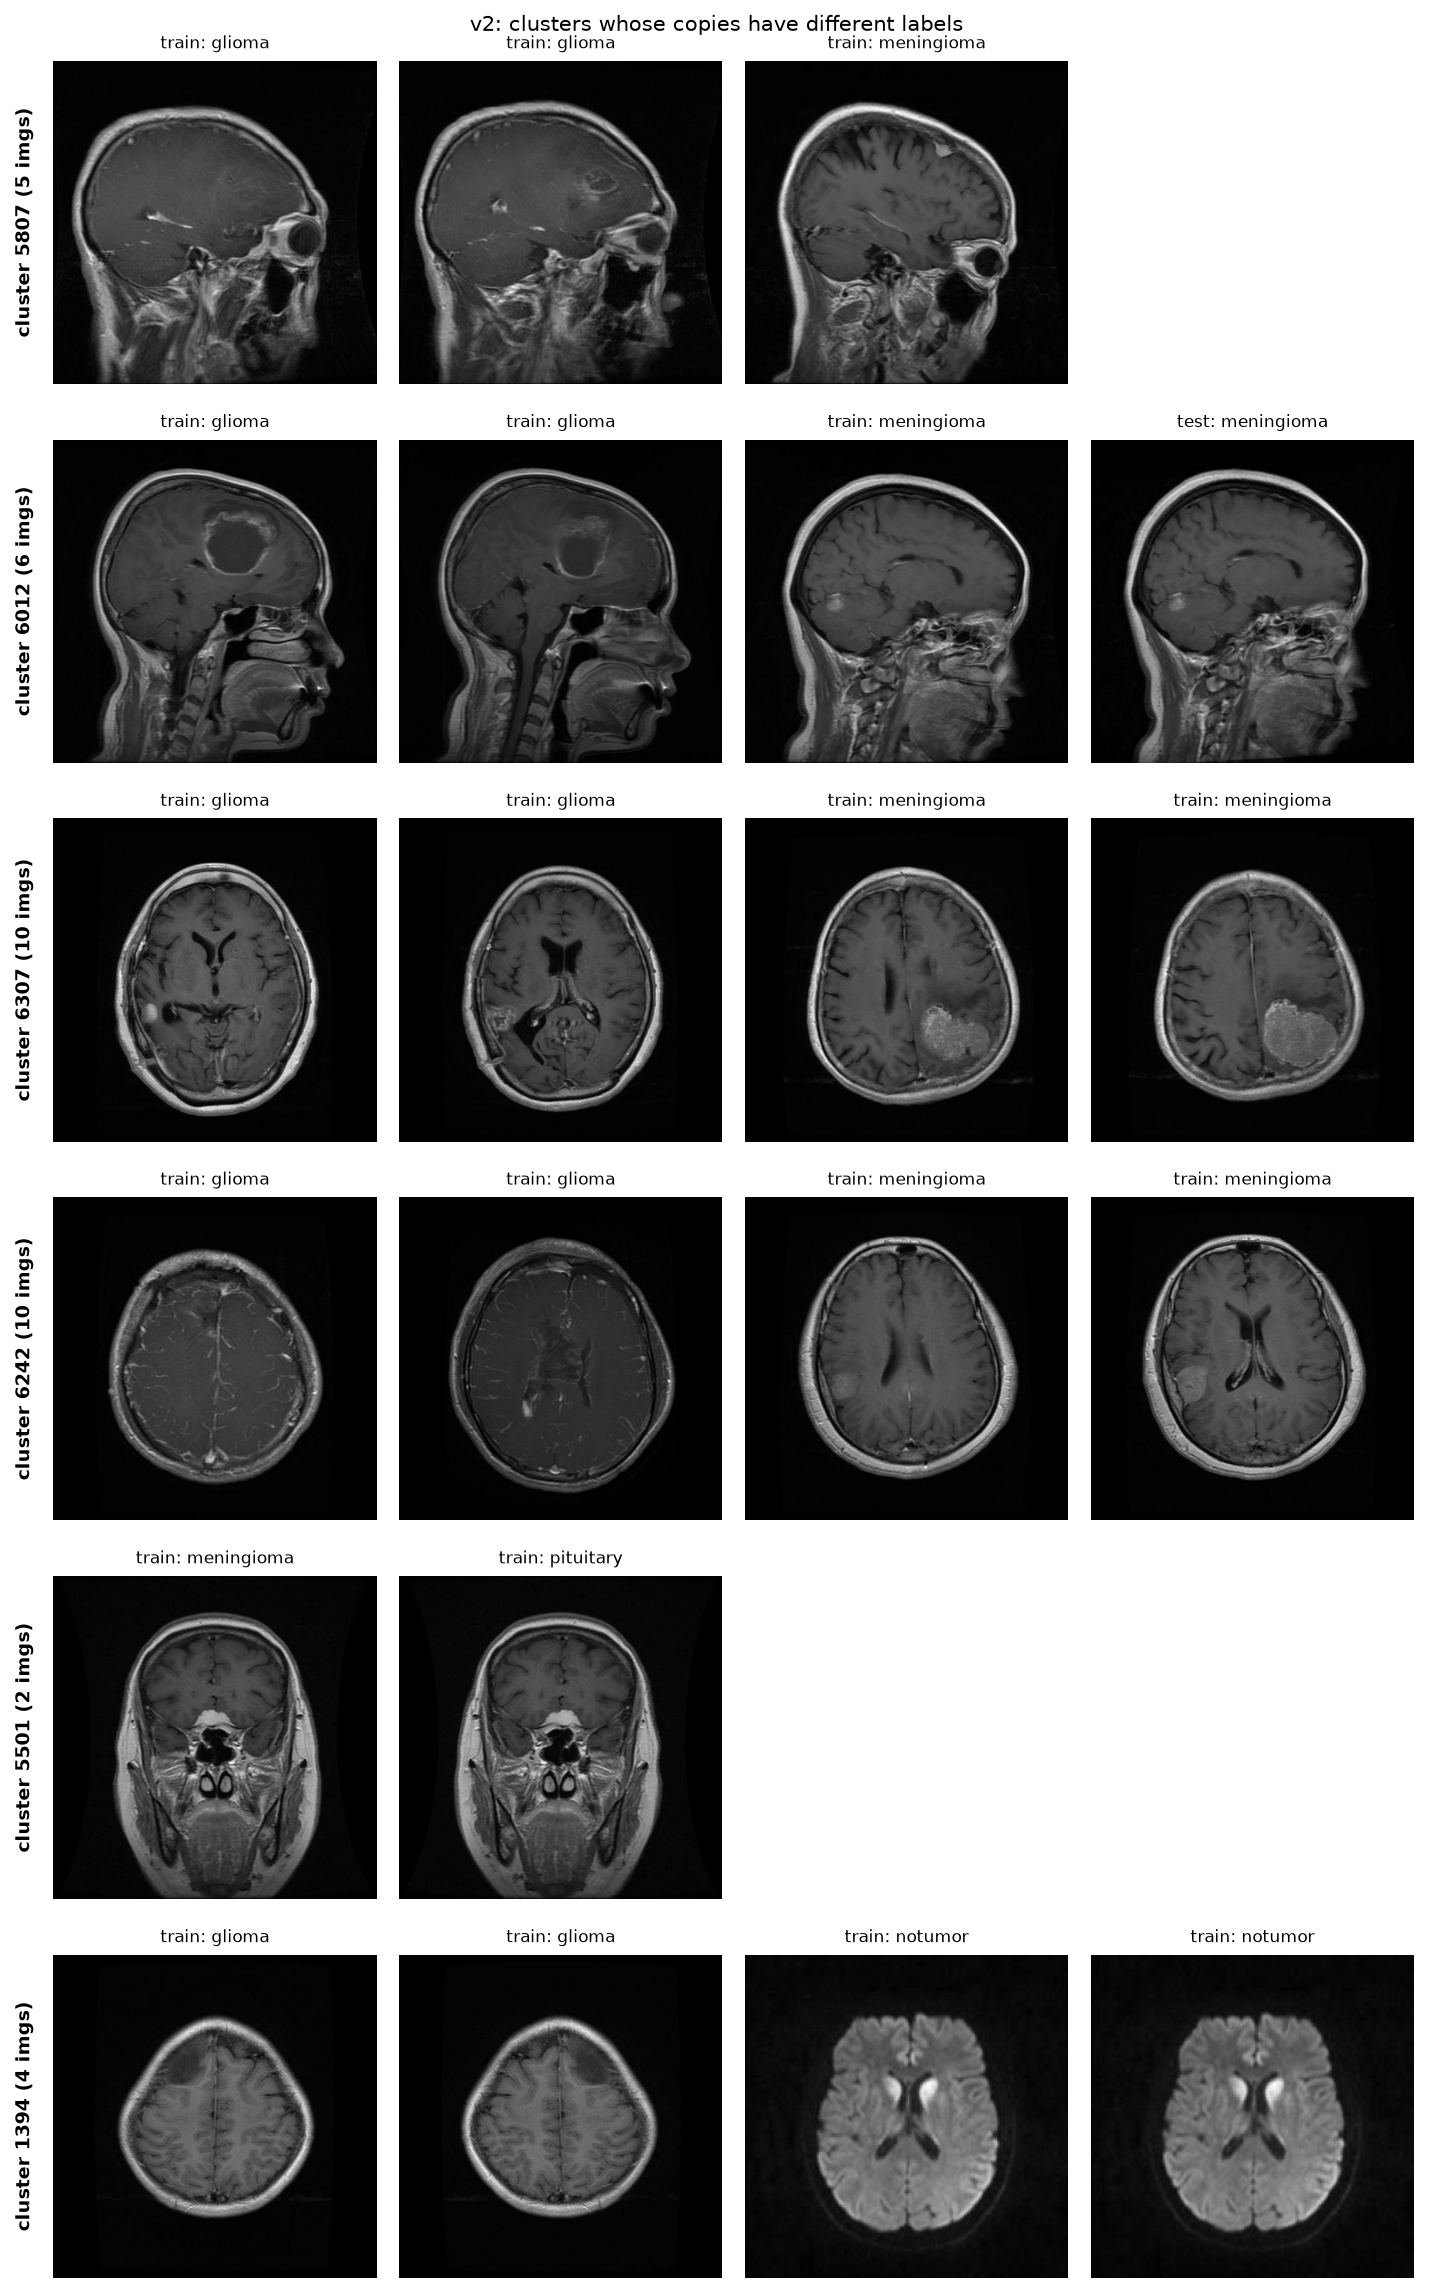

In [9]:
for v in VERSIONS:
    path = s.plot_conflict_examples(clusters[v], AUDIT[v], v)
    if path:
        display(ShowImage(filename=str(path)))

## 5. The two splits
**original:** Testing folder = test; Training folder split 85/15 into train/val (stratified). Nothing removed.

**clean:** (1) drop conflicting clusters, (2) keep the highest-resolution image of each cluster, (3) 70/15/15 stratified split. An `assert` checks that no cluster appears in two splits.

In [10]:
split_tables, dropped = {}, {}
for v in VERSIONS:
    split_tables[(v, 'original')] = s.original_split(clusters[v])
    split_tables[(v, 'clean')], dropped[v] = s.clean_split(clusters[v])   # contains the assert
    s.assert_no_cluster_crosses(split_tables[(v, 'clean')])               # checked again, explicitly
    for kind in ['original', 'clean']:
        split_tables[(v, kind)].to_csv(SPLITS / f'{v}_split_{kind}.csv', index=False)
    crossing = (split_tables[(v, 'original')].groupby('cluster_id')['split'].nunique() > 1).sum()
    print(f'{v}: clean split OK (no cluster crosses splits). Dropped: {dropped[v]}. '
          f'For comparison, {crossing} clusters cross splits in the ORIGINAL split.')
print('Saved:', sorted(p.name for p in SPLITS.glob('*_split_*.csv')))

v1: clean split OK (no cluster crosses splits). Dropped: {'conflict_images': 125, 'duplicate_copies': 3432}. For comparison, 823 clusters cross splits in the ORIGINAL split.
v2: clean split OK (no cluster crosses splits). Dropped: {'conflict_images': 175, 'duplicate_copies': 3442}. For comparison, 814 clusters cross splits in the ORIGINAL split.
Saved: ['v1_split_clean.csv', 'v1_split_original.csv', 'v2_split_clean.csv', 'v2_split_original.csv']


In [11]:
summary = s.split_summary(split_tables)
summary.to_csv(SPLITS / 'split_summary.csv', index=False)
summary

,version,split_type,split,glioma,meningioma,notumor,pituitary,total,share_%
0,v1,original,train,1123,1138,1356,1238,4855,69.1
1,v1,original,val,198,201,239,219,857,12.2
2,v1,original,test,300,306,405,300,1311,18.7
3,v1,clean,train,832,661,279,654,2426,70.0
4,v1,clean,val,178,142,60,140,520,15.0
5,v1,clean,test,179,141,60,140,520,15.0
6,v2,original,train,1190,1190,1190,1190,4760,66.1
7,v2,original,val,210,210,210,210,840,11.7
8,v2,original,test,400,400,400,400,1600,22.2
9,v2,clean,train,876,695,275,662,2508,70.0


In [12]:
# Class proportions (%) inside each split - the clean split should keep them almost equal.
props = summary.set_index(['version', 'split_type', 'split'])[d.CLASSES]
(props.div(props.sum(axis=1), axis=0) * 100).round(1)

glioma  meningioma  notumor  pituitary
version split_type split                                        
v1      original   train    23.1        23.4     27.9       25.5
                   val      23.1        23.5     27.9       25.6
                   test     22.9        23.3     30.9       22.9
        clean      train    34.3        27.2     11.5       27.0
                   val      34.2        27.3     11.5       26.9
                   test     34.4        27.1     11.5       26.9
v2      original   train    25.0        25.0     25.0       25.0
                   val      25.0        25.0     25.0       25.0
                   test     25.0        25.0     25.0       25.0
        clean      train    34.9        27.7     11.0       26.4
                   val      35.0        27.7     10.8       26.4
                   test     34.9        27.7     11.0       26.4

## 6. Final audit chart: % of test images leaked, per check type

,exact (MD5),near (pHash<=5),look-alike (cos>=0.95),any (cluster),clean split (any)
v1,7.86,55.23,57.13,70.25,0.0
v2,0.00,44.62,50.75,63.06,0.0


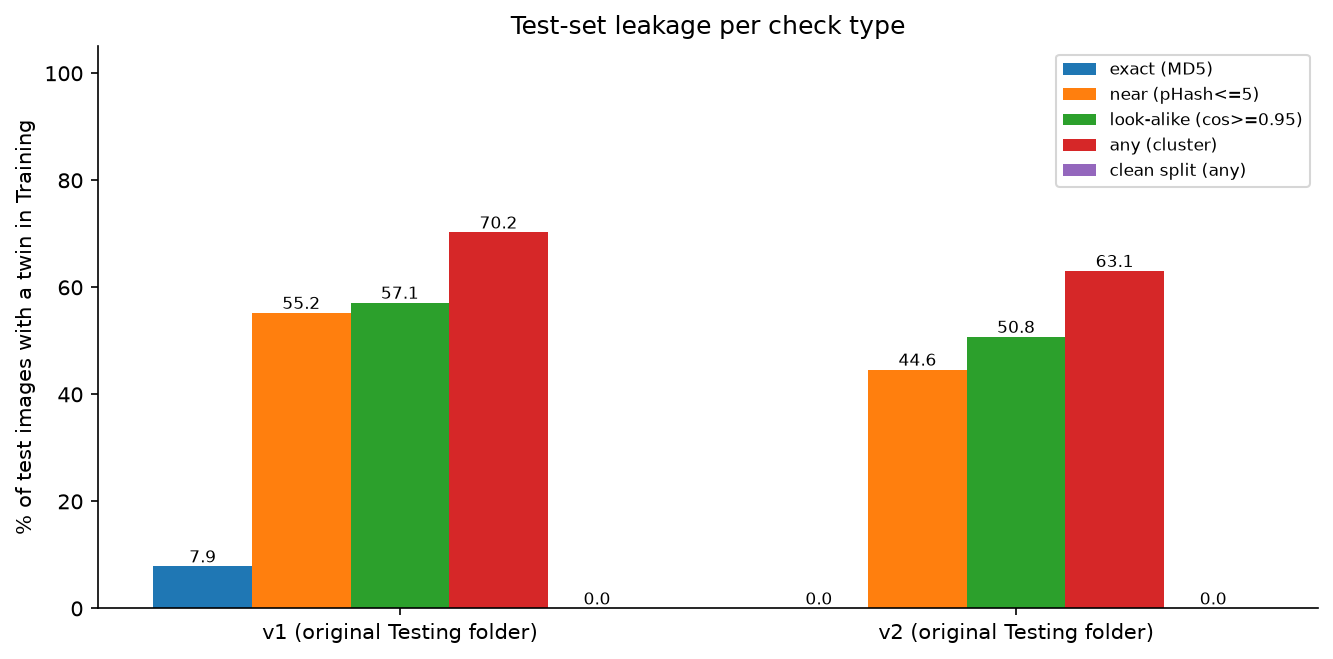

In [13]:
leaks = {v: s.leak_table(clusters[v], pairs[v], look[v]) for v in VERSIONS}
clean_leaks = {v: s.clean_test_leak(split_tables[(v, 'clean')]) for v in VERSIONS}
leak_df = pd.DataFrame(leaks).T.assign(**{'clean split (any)': pd.Series(clean_leaks)})
leak_df.to_csv('outputs/audit/leak_summary.csv')
display(leak_df)
display(ShowImage(filename=str(s.plot_leak_chart(leaks, clean_leaks, Path('outputs/audit')))))

## What we found (Week 4 summary)

**1. Look-alike check (ResNet-50, cosine >= 0.95).**
- The features are clean: 2,048 numbers per image, no NaN, and every vector has length 1.
- The GPU similarities match NumPy to within 2e-6. They take 0.33 s (v1) and 0.14 s (v2), using at most 186 MB of GPU memory.
- Two random MRIs score a cosine of 0.63 on average, and 0.83 at the 99th percentile. So 0.95 is a strict bar.
- Look-alike pairs found: v1 5,464, v2 5,024. At 0.93 / 0.97 the counts are 8,540 / 2,338 (v1).
- **Eye check:** all 8 random pairs between 0.95 and 0.96 that pHash had *not* found are the same scan. They differ only in crop, brightness, border or a ruler overlay, so 0.95 catches real copies that pHash misses.
- *Hardware note:* AMP (float16) on this GTX 1650 Ti made cuDNN return NaN for batches of 48 or more. Features are therefore computed in float32. Training must check for NaN losses.

**2. Clusters (exact + near + look-alike, union-find).**
- v1: 7,023 images become 3,483 clusters. v2: 7,200 images become 3,607 clusters.
- The largest cluster has 47 images, 0.67% of the data, so chaining does not run out of control.
- At 0.93 the largest cluster grows to 82 (v1) and 96 (v2), so 0.95 is a reasonable middle.

**3. Clusters with conflicting labels:** v1 has 17 clusters (125 images), v2 has 24 (175 images). There are two kinds:
- **True label errors:** the identical image filed under two classes, for example meningioma and pituitary in clusters 4288 and 4760.
- **Chaining:** different scans joined through a chain of look-alike links. The large clusters of 23–37 images that mix glioma, meningioma and notumor are this kind.
- Dropping all of them removes only 1.8% (v1) and 2.4% (v2) of the images. It is the safe choice.

**4. Test-set leakage, as % of the original Testing folder linked to Training:**

| check | v1 | v2 |
|---|---|---|
| exact (MD5) | 7.9 | 0.0 |
| near (pHash <= 5) | 55.2 | 44.6 |
| look-alike (cos >= 0.95) | 57.1 | 50.8 |
| **any (cluster)** | **70.2** | **63.1** |
| clean split test | **0.0** | **0.0** |

- v2's creators removed every byte-identical train-test copy (0.0%).
- But **63% of v2 test images are still linked to Training** by near copies or look-alikes.
- In the original split, 823 (v1) and 814 (v2) clusters cross between splits.

**5. The splits** (saved in `outputs/splits/`):

| | train | val | test | total |
|---|---|---|---|---|
| v1 original | 4,855 | 857 | 1,311 | 7,023 |
| v1 clean | 2,426 | 520 | 520 | 3,466 |
| v2 original | 4,760 | 840 | 1,600 | 7,200 |
| v2 clean | 2,508 | 537 | 538 | 3,583 |

- The clean split keeps one image per cluster, which is **49% (v1) and 50% (v2) of the files**. The rest are copies (3,432 / 3,442) or conflict images (125 / 175).
- The clean split is exactly 70/15/15, and the class shares are the same in train, val and test (stratified).
- The `assert` confirms that no cluster appears in two splits.
- **The clean split is unbalanced:** notumor drops to 11.5% (v1: 399 images) because most notumor files were copies. Training on the clean split will need class weights, and results must be reported with per-class and balanced metrics, not accuracy alone.

**Limitation:** chaining means some single-class clusters contain more than one real scan. Keeping one image per cluster throws those extra scans away, so the clean split is *conservative*: smaller than strictly necessary, but with no leakage.

**Next:** train the models on both splits and compare accuracy on the original split against the clean split.